# Data Interpretation

In [ ]:
from project.analysis.queries import (connect_database, fetch_role_metrics, fetch_player_history)

engine = connect_database()

medians = fetch_role_metrics(
	engine,
	role="M",
	performance_season=2025,
	min_rated_season_fraction=0.4
)

In [4]:
print("Columns:", medians.columns.to_list())
medians.head()

Columns: ['player_id', 'source_id', 'player_name', 'current_team', 'eligibility_season', 'eligibility_at', 'roles', 'performance_season', 'provider', 'season_games', 'card_risk_weight', 'imported_fixtures', 'complete_matchdays', 'coverage_status', 'rated_matches', 'fv_matches', 'mean_voto', 'mean_fv', 'median_fv', 'lower_quartile_fv', 'fv_p10', 'fv_p25', 'fv_p50', 'fv_p75', 'fv_p90', 'observed_fv_total', 'fv_lt6_matches', 'fv_ge6_matches', 'fv_ge7_matches', 'fv_ge8_matches', 'goal_sample', 'source_goals', 'source_goals_per_rated_match', 'source_goal_rate', 'assist_sample', 'assists', 'assists_per_rated_match', 'assist_rate', 'bonus_sample', 'bonus_matches', 'penalty_sample', 'penalties_scored', 'penalties_missed', 'penalty_attempts', 'card_sample', 'card_matches', 'yellow_card_sample', 'yellow_cards', 'yellow_card_rate', 'red_card_sample', 'red_cards', 'red_card_rate', 'own_goal_sample', 'own_goals', 'own_goal_rate', 'goals_conceded_sample', 'goals_conceded', 'goals_conceded_per_rated_

,player_id,source_id,player_name,current_team,eligibility_season,eligibility_at,roles,performance_season,provider,season_games,...,fv_ge7_season_fraction,fv_ge8_season_fraction,bonus_rate,penalty_conversion_rate,card_rate,observed_fv_per_season_game,season_weighted_score,role,card_weight_applies,candidate_score
0,276,1,Modric,Milan,2026,2026-09-07 17:57:58.558555+00:00,"[C, M]",2025,Redazione Fantacalcio,38,...,0.263158,0.052632,0.151515,NaN,0.121212,5.789474,5.789474,M,True,5.614035
1,294,1,Konè M.,Roma,2026,2026-09-07 17:57:58.558555+00:00,"[C, M]",2025,Redazione Fantacalcio,38,...,0.184211,0.078947,0.172414,NaN,0.068966,4.986842,4.986842,M,True,4.900862
2,255,1,Calhanoglu,Inter,2026,2026-09-07 17:57:58.558555+00:00,"[C, M]",2025,Redazione Fantacalcio,38,...,0.263158,0.210526,0.454545,0.8,0.318182,4.421053,4.421053,M,True,4.069378
3,322,1,Adopo,Cagliari,2026,2026-09-07 17:57:58.558555+00:00,"[C, M]",2025,Redazione Fantacalcio,38,...,0.052632,0.026316,0.052632,NaN,0.105263,5.881579,5.881579,M,True,5.726801
4,304,1,Cristante,Roma,2026,2026-09-07 17:57:58.558555+00:00,"[C, M]",2025,Redazione Fantacalcio,38,...,0.052632,0.052632,0.054054,NaN,0.162162,6.052632,6.052632,M,True,5.807255


In [7]:
availability = medians[["player_name", "current_team", "rated_matches", "mean_fv", "fv_p25", "fv_p50", "fv_p75", "fv_p90"]]
availability.head()

,player_name,current_team,rated_matches,mean_fv,fv_p25,fv_p50,fv_p75,fv_p90
0,Modric,Milan,33,6.666667,6.0,6.5,7.0,7.50
1,Konè M.,Roma,29,6.534483,6.0,6.5,6.5,7.60
2,Calhanoglu,Inter,22,7.636364,6.0,6.5,9.5,11.35
3,Adopo,Cagliari,38,5.881579,5.5,6.0,6.0,6.50
4,Cristante,Roma,37,6.216216,6.0,6.0,6.5,6.50


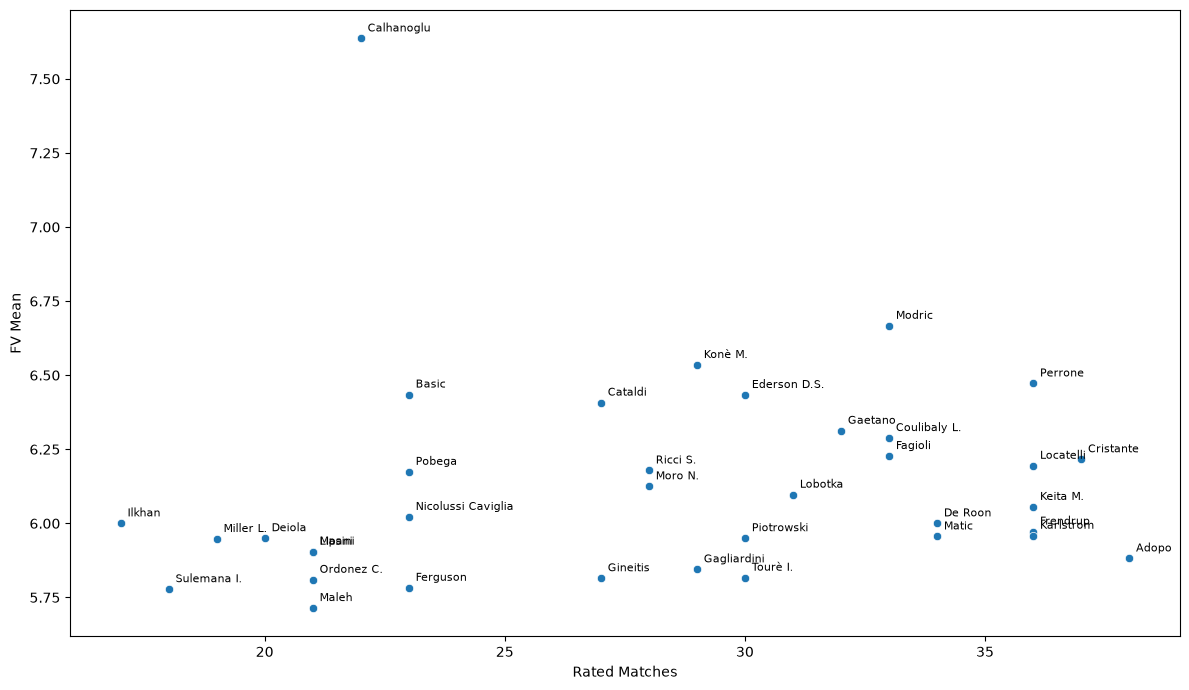

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 7))

sns.scatterplot(
	data=availability,
	x="rated_matches",
	y="mean_fv",
	ax=ax,
)

for row in availability.dropna(subset=["rated_matches", "mean_fv"]).itertuples():
	ax.annotate(
		row.player_name,
		xy=(row.rated_matches, row.mean_fv),
		xytext=(5, 5),
		textcoords="offset points",
		fontsize=8,
	)
# ax.set_ylim(6)
ax.set_ylabel("FV Mean")
ax.set_xlabel("Rated Matches")
plt.tight_layout()
plt.show()